# 06. Visualisasi Spasial Evaluasi Prediksi Model SVM
## Peta Tematik Komparasi Ground Truth vs Prediksi SVM (Benar vs Salah)

Notebook ini memuat hasil inferensi SVM dari `output/df_poligon_pred_svm.csv` dan merekonstruksi poligon spasial untuk menyajikan evaluasi spasial komprehensif:
1. **Layer Prediksi SVM per Kelas**: Poligon diwarnai sesuai kelas prediksi model.
2. **Layer Poligon Benar Diprediksi (Data Uji)**: Outline hijau terang untuk poligon uji yang terklasifikasi akurat.
3. **Layer Poligon Salah Diprediksi (Data Uji)**: Outline merah menyala dengan ketebalan khusus dan tooltip analisis mismatch `Aktual: X -> Prediksi: Y`.
4. **Grafik Pendamping Statis**: Confusion matrix dan diagram batang distribusi benar/salah per kelas yang diekspor ke `.png`.

In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import geopandas as gpd
import folium
import matplotlib.pyplot as plt
import seaborn as sns

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
OUT_DIR = BASE_DIR / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_FILE = DATA_DIR / "piksel_s2.csv"
PRED_FILE = OUT_DIR / "df_poligon_pred_svm.csv"

if not DATA_FILE.exists():
    raise FileNotFoundError(f"File {DATA_FILE} tidak ditemukan!")

if not PRED_FILE.exists():
    raise FileNotFoundError(
        f"File {PRED_FILE} belum tersedia! Jalankan notebook '04_modeling_evaluasi_svm.ipynb' terlebih dahulu."
    )

print("Memuat data piksel dan hasil prediksi poligon SVM...")
df_pix = pd.read_csv(DATA_FILE)
df_pred = pd.read_csv(PRED_FILE)
print(f"Data prediksi termuat: {len(df_pred)} poligon")

Memuat data piksel dan hasil prediksi poligon SVM...


Data prediksi termuat: 357 poligon


### 1. Analisis Kuantitatif Evaluasi Data Uji

=== RINGKASAN EVALUASI PREDIKSI DATA UJI (72 POLIGON) ===
Benar Terprediksi : 64 poligon (88.89%)
Salah Terprediksi : 8 poligon (11.11%)

Daftar Poligon yang Salah Terprediksi:


,poligon_id,label_teks,pred_svm_teks,confidence
120,Hutan_0000,Hutan,Sawah,0.348594
141,Hutan_0021,Hutan,Bangunan,0.355831
142,Hutan_0022,Hutan,Sawah,0.624898
174,Hutan_0054,Hutan,Bangunan,0.813422
259,Mangrove_0020,Mangrove,Sawah,0.285234
274,Mangrove_0035,Mangrove,Sawah,0.674825
337,Sawah_0040,Sawah,Danau,0.810408
341,Sawah_0044,Sawah,Bangunan,0.548400


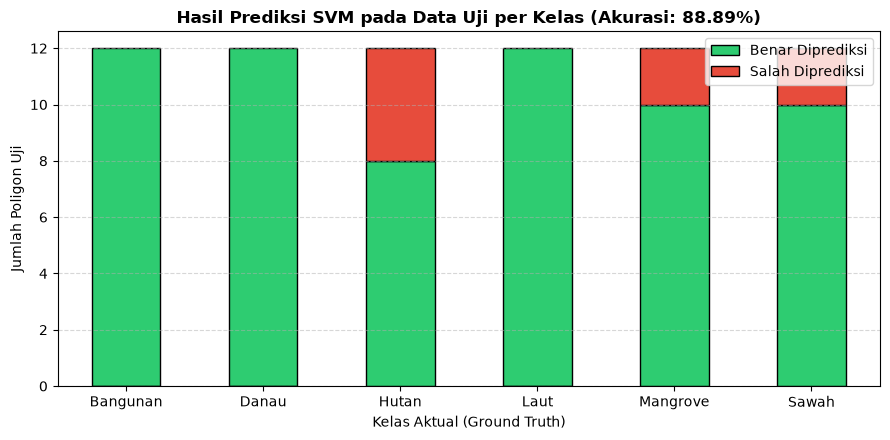

Grafik evaluasi bar tersimpan di: D:\tugas psd\website-jupyterbook\UTS\output\06_evaluasi_prediksi_bar.png


In [2]:
df_test = df_pred[df_pred['split'] == 'Test'].copy()

benar_count = int((df_test['benar'] == True).sum())
salah_count = int((df_test['benar'] == False).sum())
total_test = len(df_test)
akurasi_test = (benar_count / total_test) * 100

print(f"=== RINGKASAN EVALUASI PREDIKSI DATA UJI (72 POLIGON) ===")
print(f"Benar Terprediksi : {benar_count} poligon ({akurasi_test:.2f}%)")
print(f"Salah Terprediksi : {salah_count} poligon ({100 - akurasi_test:.2f}%)")

print("\nDaftar Poligon yang Salah Terprediksi:")
df_salah = df_test[df_test['benar'] == False][['poligon_id', 'label_teks', 'pred_svm_teks', 'confidence']]
display(df_salah)

# Visualisasi Bar Chart Benar vs Salah per Kelas
rekap_kelas = df_test.groupby(['label_teks', 'benar']).size().unstack(fill_value=0)
rekap_kelas = rekap_kelas.rename(columns={True: 'Benar', False: 'Salah'})
if 'Benar' not in rekap_kelas.columns: rekap_kelas['Benar'] = 0
if 'Salah' not in rekap_kelas.columns: rekap_kelas['Salah'] = 0

fig, ax = plt.subplots(figsize=(9, 4.5))
rekap_kelas[['Benar', 'Salah']].plot(
    kind='bar', stacked=True, color=['#2ECC71', '#E74C3C'], ax=ax, edgecolor='black'
)
plt.title(f'Hasil Prediksi SVM pada Data Uji per Kelas (Akurasi: {akurasi_test:.2f}%)', fontsize=12, fontweight='bold')
plt.xlabel('Kelas Aktual (Ground Truth)', fontsize=10)
plt.ylabel('Jumlah Poligon Uji', fontsize=10)
plt.legend(['Benar Diprediksi', 'Salah Diprediksi'], loc='upper right')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

png_eval_bar = OUT_DIR / "06_evaluasi_prediksi_bar.png"
plt.savefig(png_eval_bar, dpi=200)
plt.show()
print(f"Grafik evaluasi bar tersimpan di: {png_eval_bar}")

### 2. Rekonstruksi Poligon Spasial GeoPandas

In [3]:
gdf_points = gpd.GeoDataFrame(
    df_pix,
    geometry=gpd.points_from_xy(df_pix.lon, df_pix.lat),
    crs="EPSG:4326"
)

polygons = gdf_points.dissolve(by='poligon_id', aggfunc='first').reset_index()
polygons['geometry'] = polygons['geometry'].convex_hull
polygons = polygons[~polygons['geometry'].is_empty].copy()

# Gabungkan dengan dataframe prediksi SVM
cols_pred = ['poligon_id', 'label', 'label_teks', 'pred_svm', 'pred_svm_teks', 'benar', 'split', 'confidence', 'NDVI', 'NDWI']
polygons = polygons.drop(columns=[c for c in cols_pred if c in polygons.columns and c != 'poligon_id'])
polygons = polygons.merge(df_pred[cols_pred], on='poligon_id', how='left')

print(f"Poligon siap dipetakan: {len(polygons)} poligon")

Poligon siap dipetakan: 357 poligon


### 3. Pembuatan Peta Interaktif Evaluasi Prediksi SVM

In [4]:
colors = {
    'Sawah': '#FFD92F',
    'Bangunan': '#E41A1C',
    'Hutan': '#2E7D32',
    'Danau': '#4FC3F7',
    'Laut': '#0D47A1',
    'Mangrove': '#8E44AD'
}

map_center = [df_pix['lat'].mean(), df_pix['lon'].mean()]
m = folium.Map(
    location=map_center,
    zoom_start=9,
    tiles='https://mt1.google.com/vt/lyrs=m&x={x}&y={y}&z={z}',
    attr='Google Maps'
)

folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri World Imagery',
    name='Esri Satellite',
    overlay=False,
    control=True
).add_to(m)

folium.TileLayer(
    tiles='https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}',
    attr='Google Satellite',
    name='Google Satellite',
    overlay=False,
    control=True
).add_to(m)

# 1. Feature Groups Prediksi SVM per Kelas
fg_pred_kelas = {}
for label in ['Sawah', 'Bangunan', 'Hutan', 'Danau', 'Laut', 'Mangrove']:
    fg = folium.FeatureGroup(name=f"Prediksi: {label}", show=True)
    fg_pred_kelas[label] = fg
    m.add_child(fg)

# 2. Feature Group Benar Diprediksi (Data Uji)
fg_benar = folium.FeatureGroup(name="Data Uji: Benar Diprediksi (Outline Hijau)", show=True)
m.add_child(fg_benar)

# 3. Feature Group Salah Diprediksi (Data Uji)
fg_salah = folium.FeatureGroup(name="Data Uji: Salah Diprediksi (Outline Merah)", show=True)
m.add_child(fg_salah)

# Render Poligon ke Peta
for idx, row in polygons.iterrows():
    pred_label = str(row['pred_svm_teks'])
    color = colors.get(pred_label, '#333333')
    is_test = (row['split'] == 'Test')
    is_correct = bool(row['benar'])
    
    tooltip_text = (
        f"<b>Prediksi: {pred_label}</b> | Aktual: {row['label_teks']}<br>"
        f"Poligon ID: {row['poligon_id']} ({row['split']})<br>"
        f"Confidence: {row['confidence']*100:.1f}%"
    )
    
    popup_content = (
        f"<div style='font-family: Arial; font-size: 12px; width: 220px;'>"
        f"<h4 style='margin: 0 0 5px 0; color: {color};'>Prediksi: {pred_label}</h4>"
        f"<b>Aktual:</b> {row['label_teks']}<br>"
        f"<b>Status:</b> {'Benar' if is_correct else 'Salah Prediksi'}<br>"
        f"<b>Split:</b> {row['split']}<br>"
        f"<b>Confidence:</b> {row['confidence']*100:.1f}%<br>"
        f"<b>NDVI:</b> {row.get('NDVI', 0):.3f} | <b>NDWI:</b> {row.get('NDWI', 0):.3f}<br>"
        f"</div>"
    )
    
    # Masukkan ke FeatureGroup Prediksi Kelas
    try:
        folium.GeoJson(
            data=row['geometry'].__geo_interface__,
            style_function=lambda x, c=color: {
                'fillColor': c,
                'color': c,
                'weight': 1,
                'fillOpacity': 0.65
            },
            tooltip=tooltip_text,
            popup=folium.Popup(popup_content, max_width=250)
        ).add_to(fg_pred_kelas[pred_label])
        
        # Tambahan overlay khusus data uji
        if is_test:
            if is_correct:
                folium.GeoJson(
                    data=row['geometry'].__geo_interface__,
                    style_function=lambda x: {
                        'fillColor': '#2ECC71',
                        'color': '#27AE60',
                        'weight': 2.5,
                        'fillOpacity': 0.15
                    },
                    tooltip=f"BENAR: {row['label_teks']} (ID: {row['poligon_id']})"
                ).add_to(fg_benar)
            else:
                folium.GeoJson(
                    data=row['geometry'].__geo_interface__,
                    style_function=lambda x: {
                        'fillColor': '#E74C3C',
                        'color': '#C0392B',
                        'weight': 4,
                        'fillOpacity': 0.35
                    },
                    tooltip=f"SALAH: Aktual {row['label_teks']} -> Prediksi {pred_label} (ID: {row['poligon_id']})"
                ).add_to(fg_salah)
    except Exception as e:
        pass

# Legenda dan Ringkasan Metrik HTML
legend_eval_html = f'''
<div style="position: fixed; 
     bottom: 30px; left: 30px; width: 220px; height: 270px; 
     background-color: white; border:2px solid #bbb; z-index:9999; font-size:11px;
     padding: 10px; border-radius: 6px; box-shadow: 2px 2px 6px rgba(0,0,0,0.2);">
     <p style="margin:0 0 6px 0; font-weight: bold; border-bottom: 1px solid #ddd; padding-bottom: 3px;">Legenda Prediksi SVM</p>
     <i style="background: #FFD92F; width: 11px; height: 11px; float: left; margin-right: 6px; border: 1px solid #888;"></i> Sawah<br>
     <i style="background: #E41A1C; width: 11px; height: 11px; float: left; margin-right: 6px; border: 1px solid #888;"></i> Bangunan<br>
     <i style="background: #2E7D32; width: 11px; height: 11px; float: left; margin-right: 6px; border: 1px solid #888;"></i> Hutan<br>
     <i style="background: #4FC3F7; width: 11px; height: 11px; float: left; margin-right: 6px; border: 1px solid #888;"></i> Danau<br>
     <i style="background: #0D47A1; width: 11px; height: 11px; float: left; margin-right: 6px; border: 1px solid #888;"></i> Laut<br>
     <i style="background: #8E44AD; width: 11px; height: 11px; float: left; margin-right: 6px; border: 1px solid #888;"></i> Mangrove<br>
     <hr style="margin: 6px 0;">
     <p style="margin:0 0 4px 0; font-weight: bold;">Evaluasi Data Uji (N={total_test})</p>
     <span style="color: #27AE60; font-weight: bold;">&#9632; Benar: {benar_count} ({akurasi_test:.1f}%)</span><br>
     <span style="color: #C0392B; font-weight: bold;">&#9632; Salah: {salah_count} ({100-akurasi_test:.1f}%)</span>
</div>
'''
m.get_root().html.add_child(folium.Element(legend_eval_html))
folium.LayerControl(collapsed=False).add_to(m)

berkas_peta_svm = OUT_DIR / "peta_prediksi_svm.html"
m.save(str(berkas_peta_svm))
print(f"Peta evaluasi prediksi SVM tersimpan di: {berkas_peta_svm.resolve()}")
print(f"Ukuran berkas: {berkas_peta_svm.stat().st_size:,} bytes")
print("=== DAFTAR BERKAS KELUARAN NOTEBOOK 06 ===")
for f in [berkas_peta_svm, png_eval_bar]:
    print(f"- {f.name} ({f.stat().st_size:,} bytes)")

Peta evaluasi prediksi SVM tersimpan di: D:\tugas psd\website-jupyterbook\UTS\output\peta_prediksi_svm.html
Ukuran berkas: 1,356,111 bytes
=== DAFTAR BERKAS KELUARAN NOTEBOOK 06 ===
- peta_prediksi_svm.html (1,356,111 bytes)
- 06_evaluasi_prediksi_bar.png (68,013 bytes)


### 4. Tampilan Peta Interaktif Prediksi Model di Notebook

In [5]:
m